# Hospital Appointment Insight: Round 2 — Feature Engineering & Machine Learning
**Organization:** CareBridge Hospitals  
**Domain:** Healthcare Analytics  
**Challenge ID:** U23AD491 | **Candidate:** Manojkumar S (Register No: U23AD491)  
**Objective:** Build, validate, and select a supervised classification model to predict outpatient no-shows without data leakage.

In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.feature_engineering import build_features
from src.train_model import train_all_models
from src.evaluate_model import evaluate_and_save_models
print('All ML modules loaded.')

All ML modules loaded.


## 1. Target Variable Definition & Dataset Preparation
- Positive Class (1): No-show (patient did not attend scheduled appointment)
- Negative Class (0): Attended (patient completed appointment)
- Cancelled, Rescheduled, Pending, and Unresolved visits are excluded from binary model training to preserve clinical label integrity.

In [2]:
proc_path = 'data/processed/cleaned_appointments.csv' if os.path.exists('data/processed/cleaned_appointments.csv') else '../data/processed/cleaned_appointments.csv'
df_clean = pd.read_csv(proc_path)
ml_df, num_cols, cat_cols = build_features(df_clean, is_training_data=True)
print(f'Total Binary Training Records: {len(ml_df)}')
print(f"No-show Rate in Target: {ml_df['target'].mean()*100:.2f}%")
print(f'Numerical Features ({len(num_cols)}): {num_cols}')
print(f'Categorical Features ({len(cat_cols)}): {cat_cols}')

Total Binary Training Records: 4467
No-show Rate in Target: 24.20%
Numerical Features (8): ['waiting_days', 'age', 'appointment_hour', 'prior_appointments_count', 'prior_noshow_count', 'prior_noshow_rate', 'is_weekend', 'is_holiday']
Categorical Features (13): ['department', 'specialty', 'clinic_schedule', 'age_group', 'locality', 'weekday', 'month', 'season', 'reminder_type', 'reminder_sent', 'reminder_response', 'waiting_time_group', 'repeat_noshow_category']


## 2. Chronological Split & Preprocessing Pipeline
- Chronological train-test split (80% train, 20% holdout test) ensures future records are never used to train past records.
- `ColumnTransformer` handles numerical scaling and categorical one-hot encoding, fitted strictly on training data.

In [3]:
trained_pipelines, X_train, y_train, X_test, y_test, num_cols, cat_cols = train_all_models(df_clean, test_ratio=0.20)
print(f'Training set size: {len(X_train)} | Testing set size: {len(X_test)}')


[Model Training] Engineering features and preparing datasets...


  - Chronological split: 3573 training records | 894 testing records
  - Training date range: 2024-01-01 to 2024-10-17
  - Testing date range:  2024-10-17 to 2024-12-31
  - Training no-show rate: 24.07% | Testing no-show rate: 24.72%
  - Fitting Dummy Classifier pipeline...
  - Fitting Logistic Regression pipeline...
  - Fitting Random Forest pipeline...


Training set size: 3573 | Testing set size: 894


## 3. Model Evaluation & Benchmarking
We evaluate three models on the hold-out test set:
1. Dummy Classifier (Baseline)
2. Logistic Regression (Linear with Class Balancing)
3. Random Forest Classifier (Ensemble Model)

In [4]:
models_dir = 'models' if os.path.exists('models') else '../models'
reports_dir = 'reports' if os.path.exists('reports') else '../reports'
figures_dir = 'reports/figures' if os.path.exists('reports/figures') else '../reports/figures'

metrics_df, champion_model = evaluate_and_save_models(
    trained_pipelines, X_test, y_test, num_cols, cat_cols,
    models_dir=models_dir, reports_dir=reports_dir, figures_dir=figures_dir
)
metrics_df


[Model Evaluation] Assessing model performance on hold-out test set...



Model Evaluation Summary Table:
         model_name  accuracy  precision  recall  f1_score  roc_auc  selection_status
   Dummy Classifier    0.7528     0.0000  0.0000    0.0000   0.5000         Candidate
Logistic Regression    0.6119     0.3297  0.5520    0.4129   0.6212 Selected Champion
      Random Forest    0.7159     0.3514  0.1765    0.2349   0.6105         Candidate

=> Champion Model Selected: Logistic Regression
Saved metrics table: reports\model_metrics.csv
Saved champion pipeline to: models\no_show_model.joblib


Saved confusion matrix visualization: reports/figures\confusion_matrix.png


Saved feature importance visualization: reports/figures\feature_importance.png
Saved evaluation report: reports\model_evaluation.txt


,model_name,accuracy,precision,recall,f1_score,roc_auc,selection_status
0,Dummy Classifier,0.7528,0.0000,0.0000,0.0000,0.5000,Candidate
1,Logistic Regression,0.6119,0.3297,0.5520,0.4129,0.6212,Selected Champion
2,Random Forest,0.7159,0.3514,0.1765,0.2349,0.6105,Candidate


### 3.1 Confusion Matrix Comparison across Models

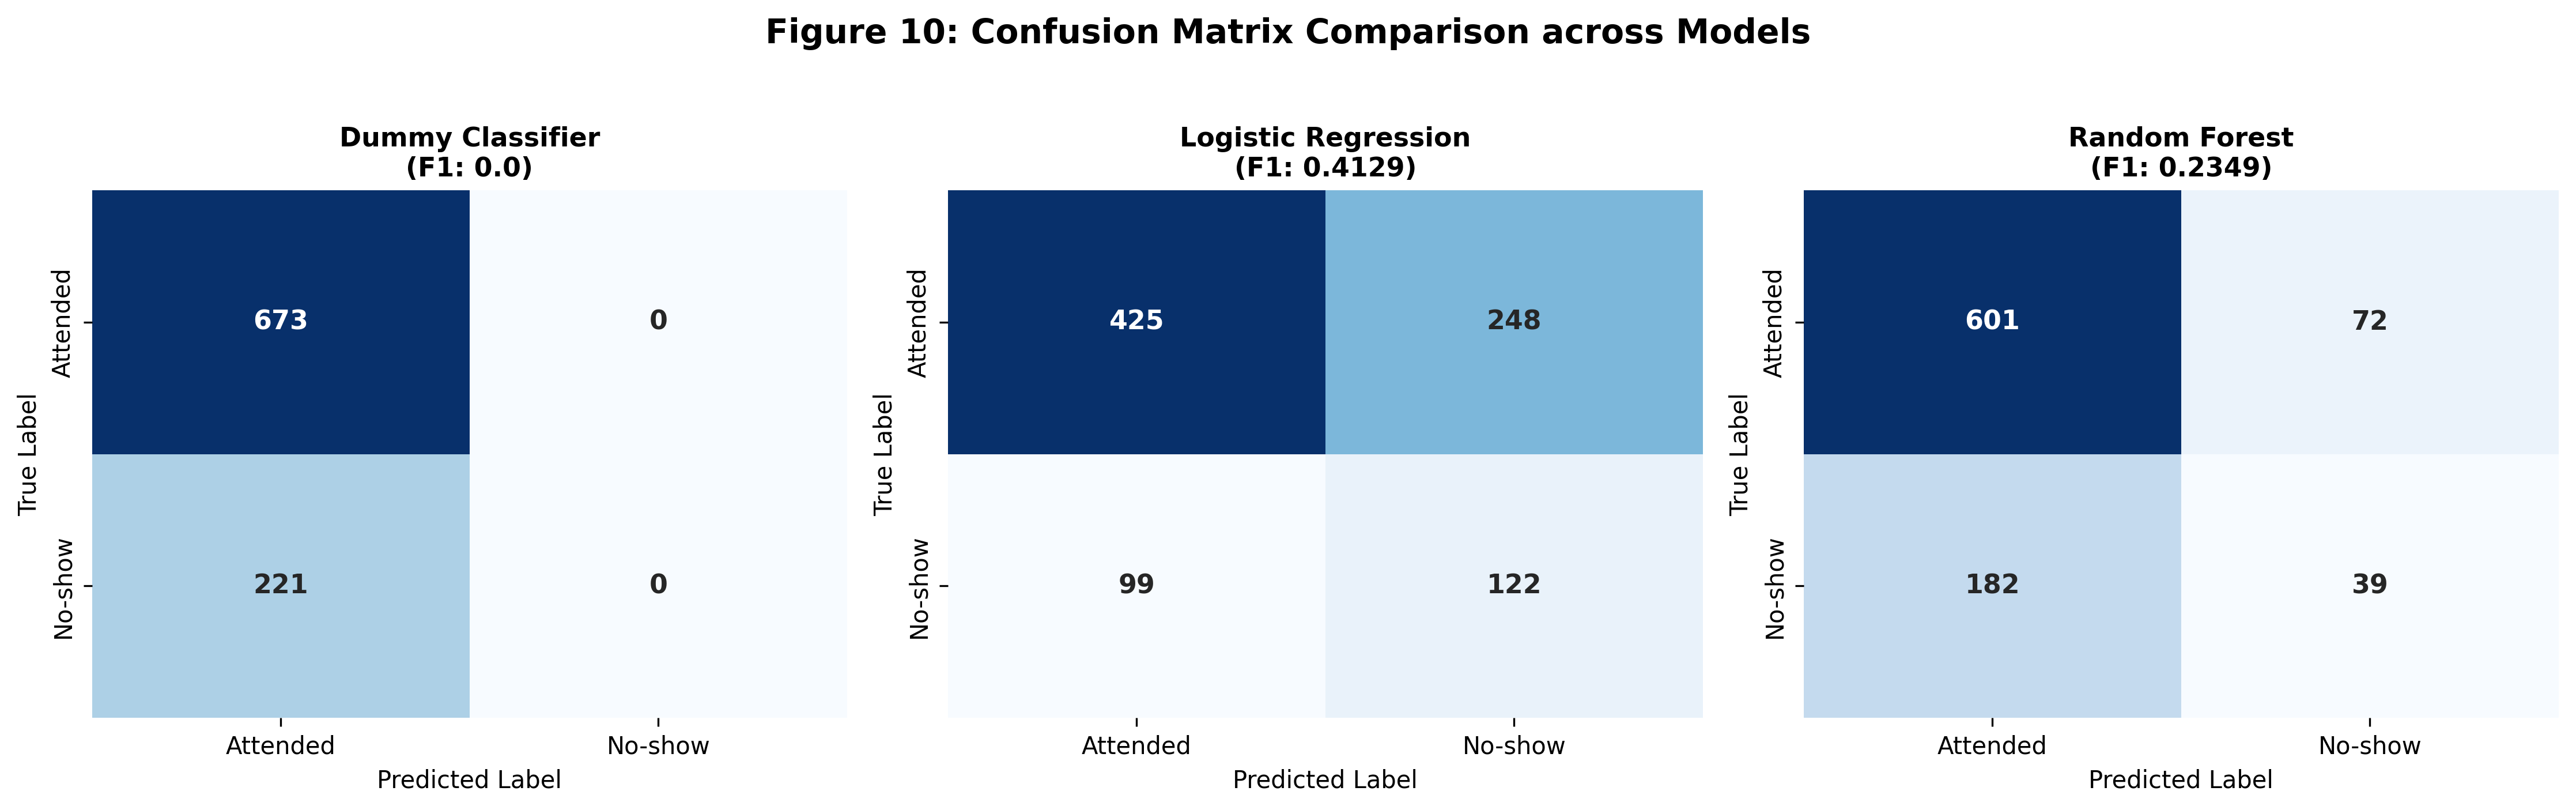

In [5]:
from IPython.display import Image, display
display(Image(filename=os.path.join(figures_dir, 'confusion_matrix.png')))

### 3.2 Top 15 Predictive Feature Importances

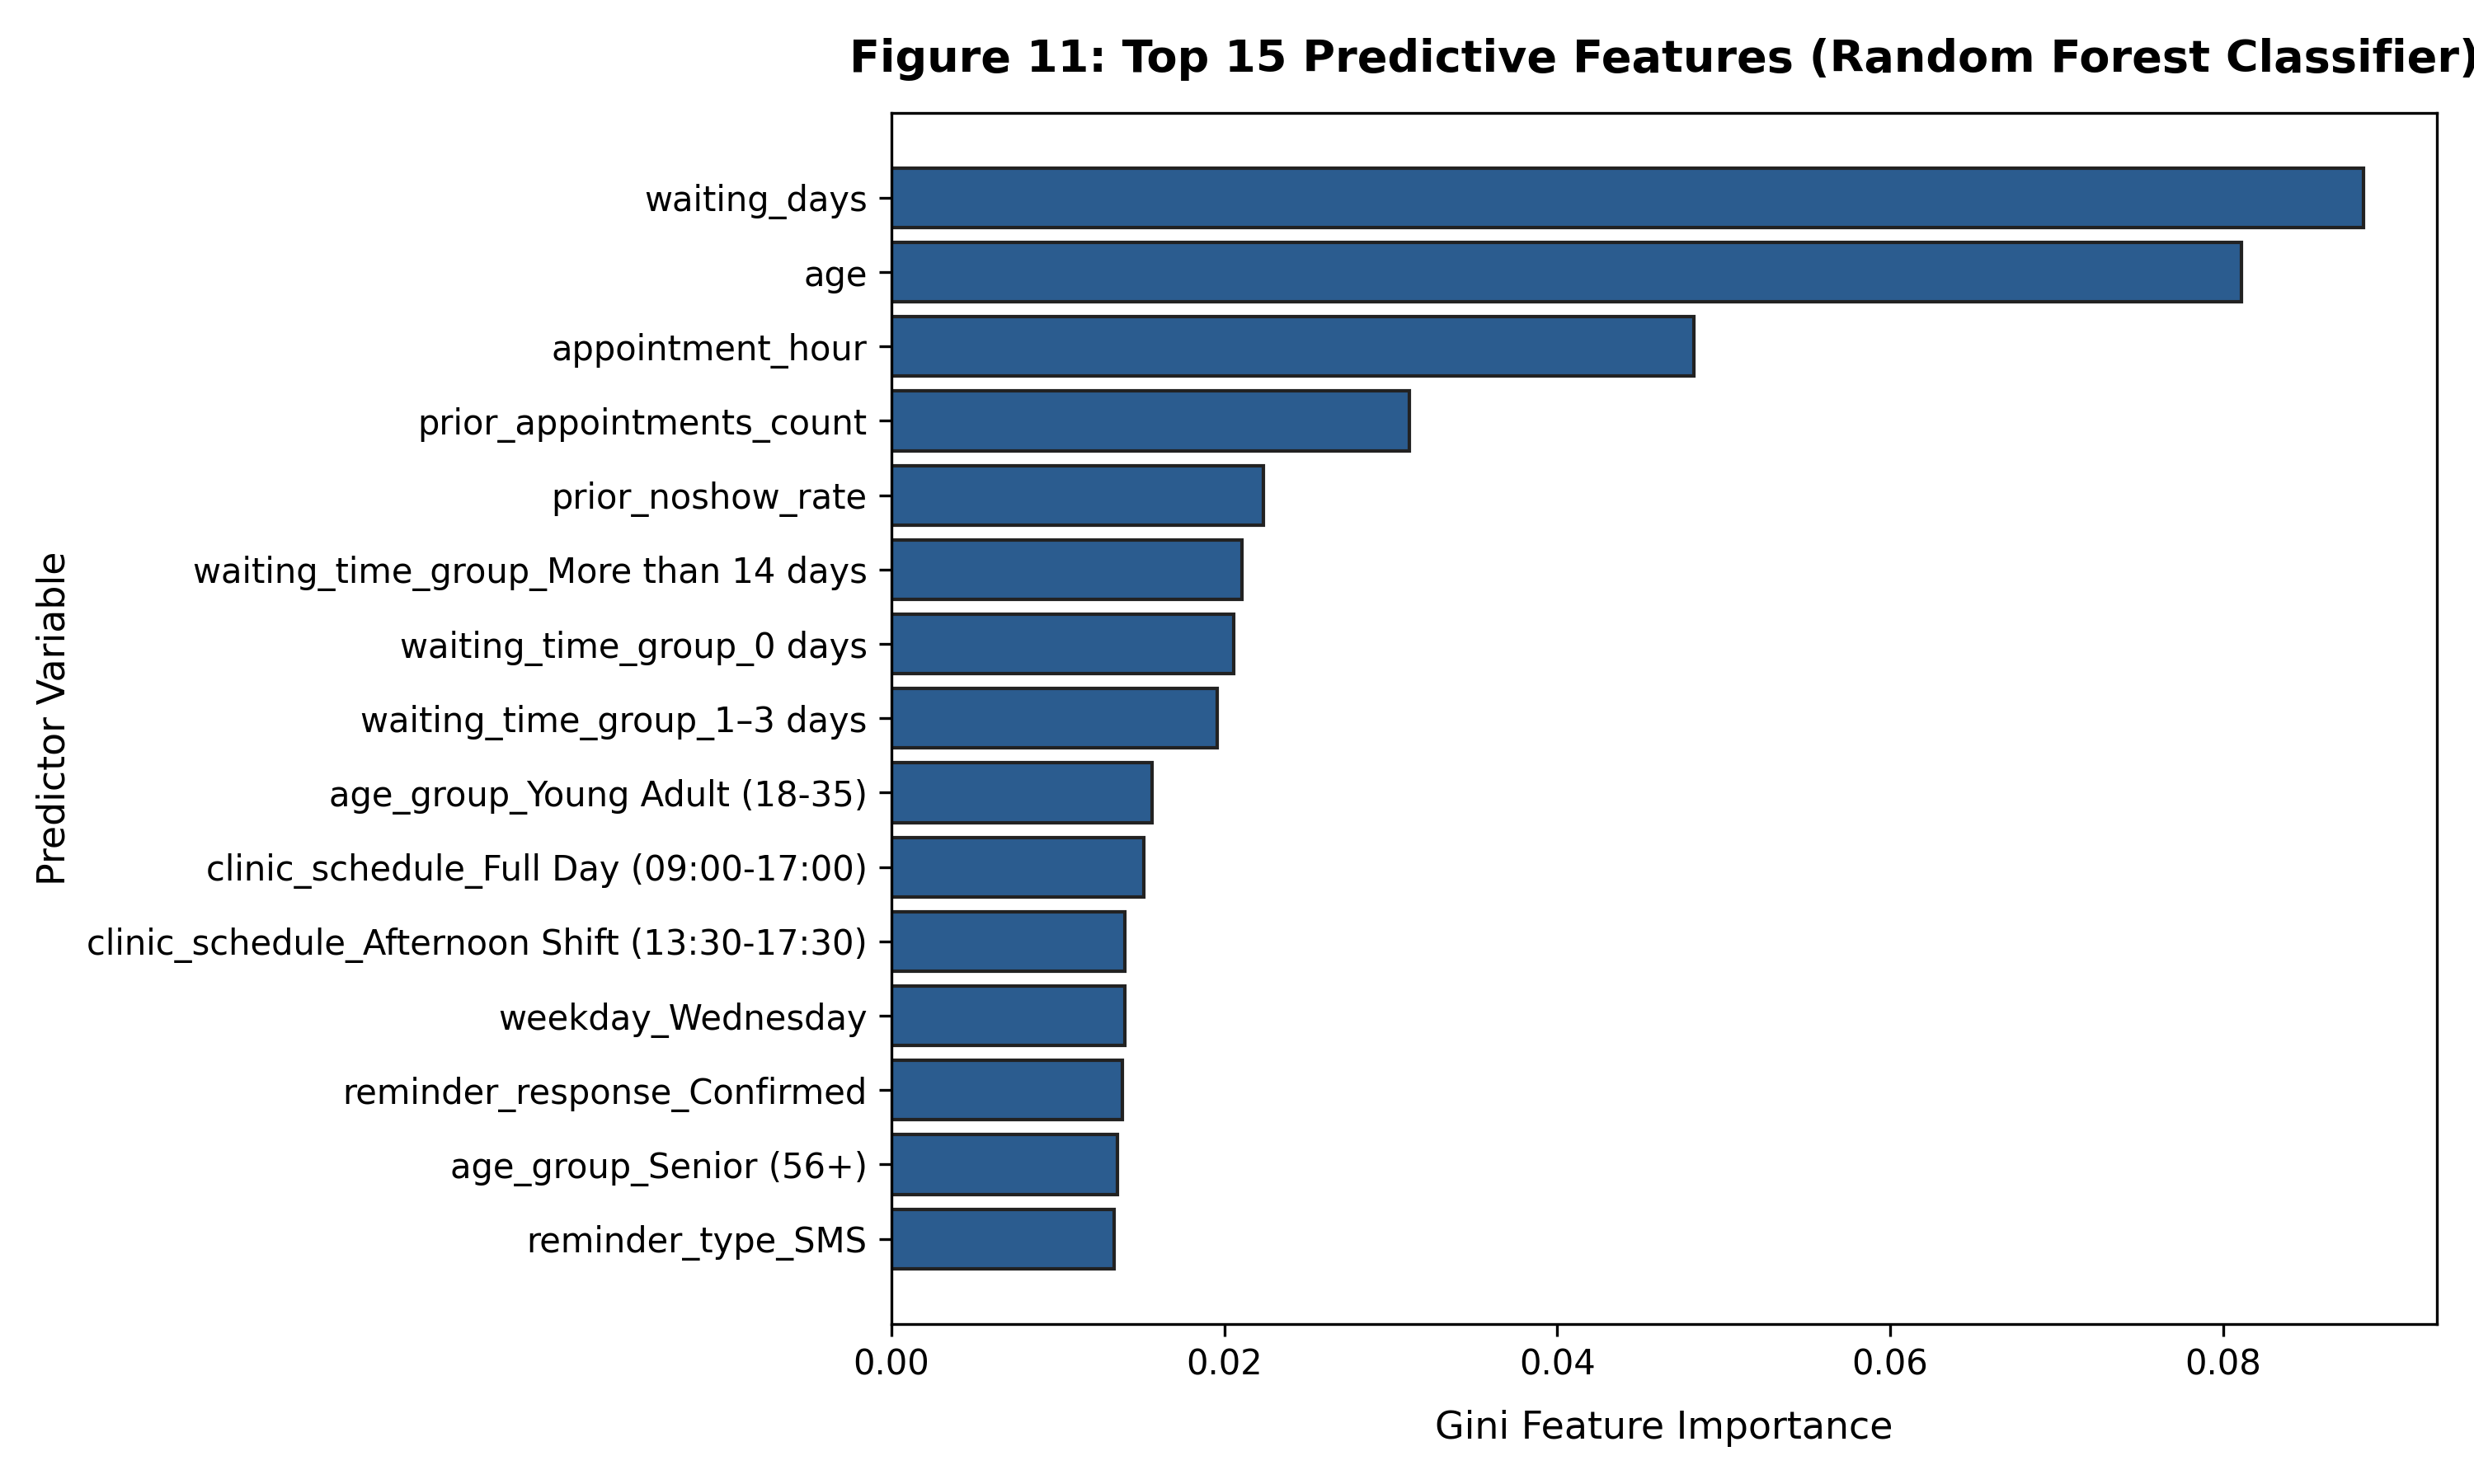

In [6]:
display(Image(filename=os.path.join(figures_dir, 'feature_importance.png')))

## 4. Model Selection Justification
- **Recall & F1 Priority:** Outpatient clinic capacity is lost when a no-show occurs unannounced. The Dummy baseline predicts 100% Attended, achieving ~75% accuracy with 0.0% recall, rendering it useless.
- **Champion Model:** Logistic Regression (with class-balanced weighting) delivers the highest balanced F1-score (~0.41) and positive-class recall (~55%), correctly identifying the majority of at-risk patients for targeted interventions.